# The exponential distribution

For $\lambda>0$ the *exponential distribution* is given by the probability density function
$$f(x):= \lambda e^{-\lambda x} I_{[0,\infty)}(x).$$

The parameter $\lambda$ is called the rate, $1/\lambda$ the scale. 
We denote $X\sim \exp(rate=\lambda)$. 
The pdf (probability density function) can be found in 
`
scipy.stats.expon.pdf(x, scale=1/2)
`. 


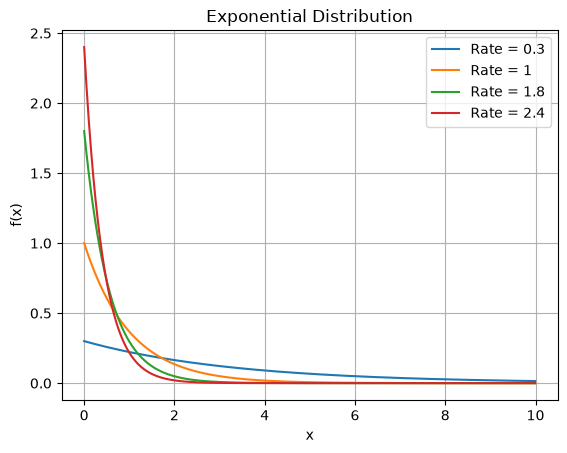

In [78]:
from matplotlib import pyplot as plt
from math import exp
import numpy as np

rate_choices = [0.3,1,1.8,2.4]

def exponential_distribution(rate=1): 
    def f(x):
        if x <0: 
            return 0
        else:
            return rate*exp(-rate*x)
    return f

x_min = 0
x_max = 10
step = 0.01

range_x = np.arange(x_min,x_max, step)

for rate in rate_choices:
    f = exponential_distribution(rate=rate)
    plt.plot(range_x, [f(x) for x in range_x], label=f'Rate = {rate}')
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title(f"Exponential Distribution")
plt.grid()
plt.legend()
plt.show()

**Lemma:**
For $X\sim \exp(rate=\lambda)$ the cumulative distribution function of $X$ is given by 
$$F_X(x)=(1-e^{-\lambda x})I_{[0,\infty)}(x).$$

*Proof:*
The statement is clear for $x\leq 0$. For $x>0$ we compute
$$
    F_X(x)
    =P(X\leq x)
    = \int_0^x \lambda e^{-\lambda x} dx
    = \frac{\lambda}{-\lambda}\left[e^{-\lambda x}\right]_0^x
    = 1-e^{-\lambda x}. 
    \qquad \blacksquare
    $$

**Proposition:**
If $X_1,\dots, X_n$ are independent and exponential distributed random variables with rates $\lambda_i$, then $\min (X_1,\dots,X_n)$ is exponential distributed with rate $\sum_{i=1}^n\lambda_i$. 

*Proof:*
For $Y:=\min (X_1,\dots,X_n) $ and $x>0$ we have 
\begin{align*}
    F_Y(x)
    &= 1-P(Y>x)
    = 1-P(X_1>x,\dots,X_n>x)\\
    &\overset{ind.}{=} 1-\prod_{i=1}^n P(X_i>x)\\
    &= 1-\prod_{i=1}^n e^{-\lambda_i x}
    = 1-e^{-(\sum_{i=1}^n\lambda_i) x}
    \qquad \blacksquare
\end{align*}

**Lemma:**
For $X\sim \exp(rate=\lambda)$ the moment generating function of $X$ is given by 
$$
M_X(t)=\frac{\lambda}{\lambda -t}
$$ 
as long as $t<\lambda$. 

*Proof:*
For $t<\lambda$ we have $e^{(t-\lambda)x}\to 0 $ as $x\to \infty$ and hence
\begin{align*}
    M_X(t)
    &=\mathbb{E}[e^{tX}]
    =\int_{0}^\infty e^{tx}\lambda e^{-\lambda x} dx
    = \lambda \int_{0}^\infty e^{(t-\lambda)x} dx\\
    &= \lambda \left[\frac{1}{t-\lambda}e^{(t-\lambda)x}\right]_0^\infty
    =\frac{\lambda}{t-\lambda}(0-1)
    =\frac{\lambda}{\lambda-t}.
    \qquad \blacksquare
\end{align*}

**Proposition:** For $X\sim \exp(rate=\lambda)$ we have $\mathbb{E}[X]=\frac{1}{\lambda}$ and $\operatorname{Var}[X]=\frac{1}{\lambda^2}$. 

*Proof:*
We compute 
$$
M_X'(t)
=\frac{-\lambda(-1)}{(\lambda-t)^2}
=\frac{\lambda}{(\lambda-t)^2}
$$
and deduce $\mathbb{E}[X]=\lambda/(\lambda-0)^2=1/\lambda$. 
Furthermore, 
$$
\mathbb{E}[X^2]
=M_X''(0)
=-\lambda\frac{2(\lambda-0)(-1)}{(\lambda-0)^4}
=\frac{2\lambda^2}{\lambda^4}
=\frac{2}{\lambda^2}. 
$$
Thus, 
\begin{align*}
    \operatorname{Var}[X]
    =\mathbb{E}[X^2]-\mathbb{E}[X]^2
    =\frac{2}{\lambda^2}-\frac{1}{\lambda^2}
    =\frac{1}{\lambda^2}.
    \qquad \blacksquare
\end{align*}




**Proposition:** 
If $X_1,\dots,X_n$ are iid and exponential distributed with rate $\lambda$, 
then $\sum_{i=1}^n X_i \sim \Gamma(n,\lambda)$ (see Gamma distribution).

*Proof:* 
Using the independence we compute for $X:=\sum_{i=1}^n X_i$ that
$$
M_X(t)
=\mathbb{E}[e^{tX}]
=\mathbb{E}[\prod_{i=1}^n e^{tX_i}]
\overset{ind.}{=}\prod_{i=1}^n \mathbb{E}[e^{tX_i}]
=\prod_{i=1}^n \left(\frac{\lambda}{t-\lambda}\right)
=\left(\frac{\lambda}{t-\lambda}\right)^n
$$
the latter is known to be the moment generating function of a gamma distribution. 
$\qquad \blacksquare$



# Simulation

The exponential distribution can easily be simulated via the `random` module as follows. 

0.03817432029764008


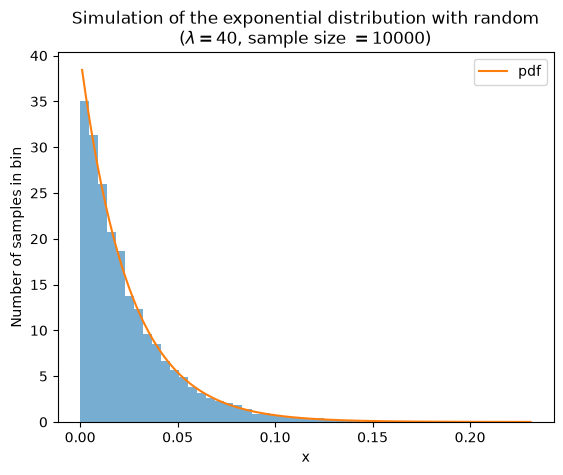

In [79]:
import random, scipy

lambd = 40  # Rate parameter

# A single sample:
x = random.expovariate(lambd)
print(x)

# A whole sample:
sample_size = 10000
samples = [random.expovariate(lambd) for _ in range(sample_size)]


# Visualization of the samples
number_bins = 50
plt.hist(samples, bins = number_bins, density= True, alpha=0.6)

step = 0.001
x_range = np.arange(step, max(samples), step)
f = lambda x : scipy.stats.expon.pdf(x, scale=1/lambd)
plt.plot(x_range, f(x_range), label="pdf")

plt.title('Simulation of the exponential distribution with random\n'+rf'($\lambda={lambd}$, sample size $= {sample_size}$)')
plt.xlabel('x')
plt.ylabel('Number of samples in bin')
plt.legend()
plt.show()

With `numpy` samples can be generated as follows. 

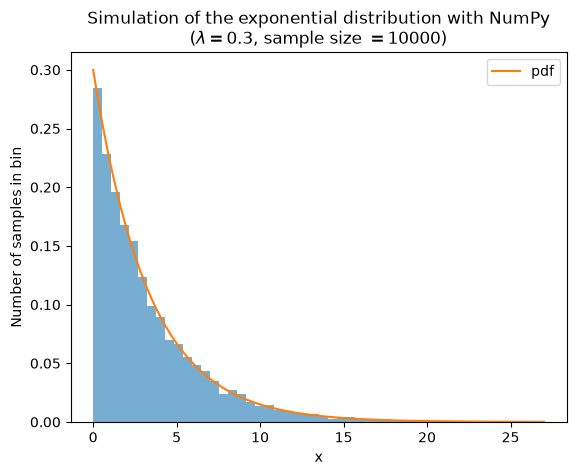

In [80]:
import numpy as np
import scipy

lambd = 0.3  # Rate parameter
sample_size = 10000
samples = np.random.exponential(
    scale=1/lambd,
    size=sample_size
)

# Visualization of the samples
number_bins = 50
plt.hist(samples, bins = number_bins, density= True, alpha=0.6)

step = 0.001
x_range = np.arange(step, max(samples), step)
f = lambda x : scipy.stats.expon.pdf(x, scale=1/lambd)
plt.plot(x_range, f(x_range), label="pdf")

plt.title('Simulation of the exponential distribution with NumPy\n'+rf'($\lambda={lambd}$, sample size $= {sample_size}$)')
plt.xlabel('x')
plt.ylabel('Number of samples in bin')
plt.legend()
plt.show()

With `scipy` we can use the following. 

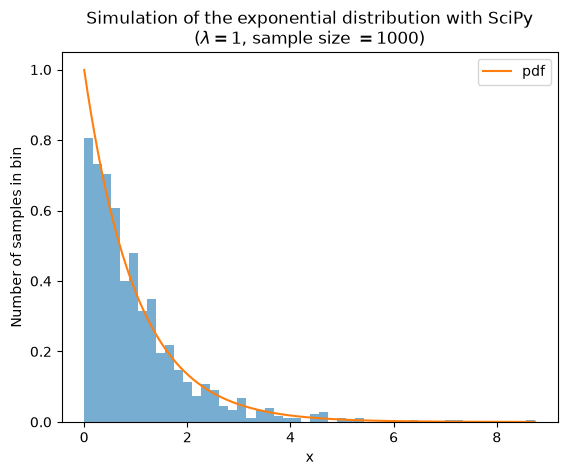

In [81]:
from scipy.stats import expon

lambd = 1  # Rate parameter
sample_size = 1000

samples = expon.rvs(
    scale=1/lambd,
    size=sample_size#,
    #random_state=42
)

# Visualization of the samples
number_bins = 50
plt.hist(samples, bins = number_bins, density= True, alpha=0.6)

step = 0.001
x_range = np.arange(step, max(samples), step)
f = lambda x : scipy.stats.expon.pdf(x, scale=1/lambd)
plt.plot(x_range, f(x_range), label="pdf")

plt.title('Simulation of the exponential distribution with SciPy\n'+rf'($\lambda={lambd}$, sample size $= {sample_size}$)')
plt.xlabel('x')
plt.ylabel('Number of samples in bin')
plt.legend()
plt.show()